In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/weekly_ae_raw.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 42825
Columns: 15


,WeekEndingDate,NHSBoardCypher,NHSBoardName,LocationCode,LocationName,DepartmentType,AttendanceCategory,NumberOfAttendancesEpisode,NumberWithin4HoursEpisode,NumberOver4HoursEpisode,PercentageWithin4HoursEpisode,NumberOver8HoursEpisode,PercentageOver8HoursEpisode,NumberOver12HoursEpisode,PercentageOver12HoursEpisode
0,2015-02-22,A,NHS Ayrshire & Arran,A210H,University Hospital Ayr,Type 1,Unplanned,814,624,190,76.7,21,2.6,2,0.2
1,2015-02-22,A,NHS Ayrshire & Arran,A210H,University Hospital Ayr,Type 1,All,814,624,190,76.7,21,2.6,2,0.2
2,2015-02-22,A,NHS Ayrshire & Arran,A111H,University Hospital Crosshouse,Type 1,Unplanned,1347,1115,232,82.8,31,2.3,2,0.1
3,2015-02-22,A,NHS Ayrshire & Arran,A111H,University Hospital Crosshouse,Type 1,All,1347,1115,232,82.8,31,2.3,2,0.1
4,2015-02-22,B,NHS Borders,B120H,Borders General Hospital,Type 1,Unplanned,517,463,54,89.6,1,0.2,0,0.0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 42825 entries, 0 to 42824
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   WeekEndingDate                 42825 non-null  str    
 1   NHSBoardCypher                 42825 non-null  str    
 2   NHSBoardName                   42825 non-null  str    
 3   LocationCode                   42825 non-null  str    
 4   LocationName                   42825 non-null  str    
 5   DepartmentType                 42825 non-null  str    
 6   AttendanceCategory             42825 non-null  str    
 7   NumberOfAttendancesEpisode     42825 non-null  int64  
 8   NumberWithin4HoursEpisode      42825 non-null  int64  
 9   NumberOver4HoursEpisode        42825 non-null  int64  
 10  PercentageWithin4HoursEpisode  42825 non-null  float64
 11  NumberOver8HoursEpisode        42825 non-null  int64  
 12  PercentageOver8HoursEpisode    42825 non-null  float64
 1

In [3]:
df.columns.tolist()

['WeekEndingDate',
 'NHSBoardCypher',
 'NHSBoardName',
 'LocationCode',
 'LocationName',
 'DepartmentType',
 'AttendanceCategory',
 'NumberOfAttendancesEpisode',
 'NumberWithin4HoursEpisode',
 'NumberOver4HoursEpisode',
 'PercentageWithin4HoursEpisode',
 'NumberOver8HoursEpisode',
 'PercentageOver8HoursEpisode',
 'NumberOver12HoursEpisode',
 'PercentageOver12HoursEpisode']

In [4]:
df.isnull().sum()

WeekEndingDate                   0
NHSBoardCypher                   0
NHSBoardName                     0
LocationCode                     0
LocationName                     0
DepartmentType                   0
AttendanceCategory               0
NumberOfAttendancesEpisode       0
NumberWithin4HoursEpisode        0
NumberOver4HoursEpisode          0
PercentageWithin4HoursEpisode    0
NumberOver8HoursEpisode          0
PercentageOver8HoursEpisode      0
NumberOver12HoursEpisode         0
PercentageOver12HoursEpisode     0
dtype: int64

In [5]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [6]:
print("Earliest date:", df["WeekEndingDate"].min())
print("Latest date:", df["WeekEndingDate"].max())

Earliest date: 2015-02-22
Latest date: 2026-09-13


In [7]:
print(df["AttendanceCategory"].value_counts())

AttendanceCategory
Unplanned      18149
All            18149
New planned     6527
Name: count, dtype: int64


In [8]:
# Convert the date column into a proper datetime format
df["WeekEndingDate"] = pd.to_datetime(df["WeekEndingDate"])

# Keep only 2023–2025 and total attendance records
df_analysis = df[
    (df["WeekEndingDate"] >= "2023-01-01") &
    (df["WeekEndingDate"] <= "2025-12-31") &
    (df["AttendanceCategory"] == "All")
].copy()

print("Original rows:", len(df))
print("Analysis rows:", len(df_analysis))
print("Start date:", df_analysis["WeekEndingDate"].min())
print("End date:", df_analysis["WeekEndingDate"].max())

Original rows: 42825
Analysis rows: 4710
Start date: 2023-01-01 00:00:00
End date: 2025-12-28 00:00:00


In [9]:
print("Number of NHS Boards:", df_analysis["NHSBoardName"].nunique())
print("Number of Hospitals:", df_analysis["LocationName"].nunique())

print("\nNHS Boards:")
print(df_analysis["NHSBoardName"].unique())

Number of NHS Boards: 14
Number of Hospitals: 30

NHS Boards:
<StringArray>
[       'NHS Ayrshire & Arran',                 'NHS Borders',
     'NHS Dumfries & Galloway',                    'NHS Fife',
            'NHS Forth Valley',                'NHS Grampian',
 'NHS Greater Glasgow & Clyde',                'NHS Highland',
             'NHS Lanarkshire',                 'NHS Lothian',
                  'NHS Orkney',                'NHS Shetland',
                 'NHS Tayside',           'NHS Western Isles']
Length: 14, dtype: str


In [10]:
lothian = df_analysis[df_analysis["NHSBoardName"] == "NHS Lothian"]

print("NHS Lothian rows:", len(lothian))

print("\nLothian hospitals:")
print(lothian["LocationName"].unique())

NHS Lothian rows: 471

Lothian hospitals:
<StringArray>
['Royal Hospital for Children and Young People Edinburgh',
                           'Royal Infirmary Of Edinburgh',
                                     'St John's Hospital']
Length: 3, dtype: str


In [11]:
# Save cleaned 2023–2025 Scotland-wide dataset
output_path = "../data/processed/ae_scotland_2023_2025.csv"

df_analysis.to_csv(output_path, index=False)

print("Saved successfully!")
print("Rows:", len(df_analysis))
print("Columns:", len(df_analysis.columns))

Saved successfully!
Rows: 4710
Columns: 15


In [12]:
# Scotland A&E headline KPIs

total_attendances = df_analysis["NumberOfAttendancesEpisode"].sum()
within_4hrs = df_analysis["NumberWithin4HoursEpisode"].sum()
over_4hrs = df_analysis["NumberOver4HoursEpisode"].sum()
over_8hrs = df_analysis["NumberOver8HoursEpisode"].sum()
over_12hrs = df_analysis["NumberOver12HoursEpisode"].sum()

performance_4hr = (within_4hrs / total_attendances) * 100

print(f"Total A&E Attendances: {total_attendances:,}")
print(f"Seen within 4 hours: {within_4hrs:,}")
print(f"4-hour performance: {performance_4hr:.2f}%")
print(f"Over 4 hours: {over_4hrs:,}")
print(f"Over 8 hours: {over_8hrs:,}")
print(f"Over 12 hours: {over_12hrs:,}")

Total A&E Attendances: 4,160,350
Seen within 4 hours: 2,716,680
4-hour performance: 65.30%
Over 4 hours: 1,443,670
Over 8 hours: 495,359
Over 12 hours: 211,891


In [13]:
# Create Year column
df_analysis["Year"] = df_analysis["WeekEndingDate"].dt.year

# Aggregate Scotland A&E performance by year
yearly = df_analysis.groupby("Year").agg(
    Total_Attendances=("NumberOfAttendancesEpisode", "sum"),
    Within_4_Hours=("NumberWithin4HoursEpisode", "sum"),
    Over_4_Hours=("NumberOver4HoursEpisode", "sum"),
    Over_8_Hours=("NumberOver8HoursEpisode", "sum"),
    Over_12_Hours=("NumberOver12HoursEpisode", "sum")
).reset_index()

# Calculate 4-hour performance rate
yearly["Performance_4hr_%"] = (
    yearly["Within_4_Hours"] /
    yearly["Total_Attendances"] * 100
).round(2)

yearly

,Year,Total_Attendances,Within_4_Hours,Over_4_Hours,Over_8_Hours,Over_12_Hours,Performance_4hr_%
0,2023,1358202,900112,458090,147596,59298,66.27
1,2024,1396536,903644,492892,174947,77473,64.71
2,2025,1405612,912924,492688,172816,75120,64.95


In [14]:
yearly[["Year", "Total_Attendances", "Performance_4hr_%"]]

,Year,Total_Attendances,Performance_4hr_%
0,2023,1358202,66.27
1,2024,1396536,64.71
2,2025,1405612,64.95


In [15]:
# Calculate year-on-year changes

yearly["Attendance_YoY_%"] = (
    yearly["Total_Attendances"].pct_change() * 100
).round(2)

yearly["Performance_Change_pp"] = (
    yearly["Performance_4hr_%"].diff()
).round(2)

yearly[[
    "Year",
    "Total_Attendances",
    "Attendance_YoY_%",
    "Performance_4hr_%",
    "Performance_Change_pp"
]]

,Year,Total_Attendances,Attendance_YoY_%,Performance_4hr_%,Performance_Change_pp
0,2023,1358202,NaN,66.27,NaN
1,2024,1396536,2.82,64.71,-1.56
2,2025,1405612,0.65,64.95,0.24


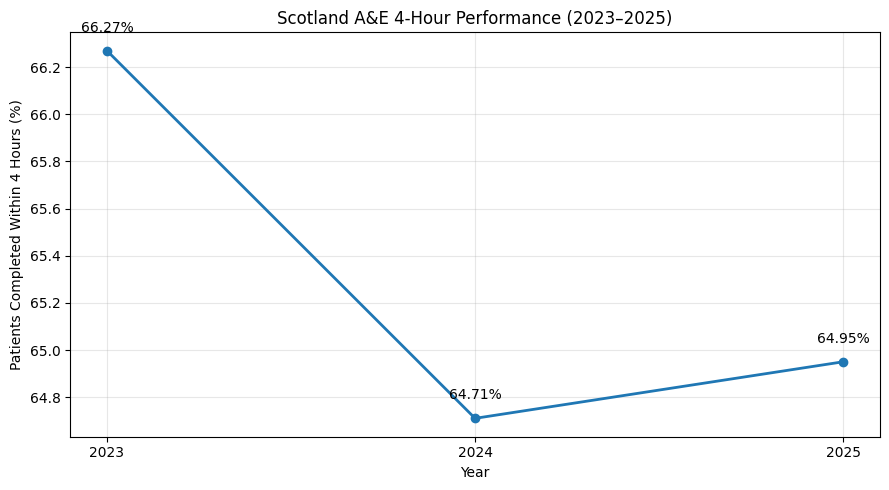

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    yearly["Year"],
    yearly["Performance_4hr_%"],
    marker="o",
    linewidth=2
)

plt.title("Scotland A&E 4-Hour Performance (2023–2025)")
plt.xlabel("Year")
plt.ylabel("Patients Completed Within 4 Hours (%)")
plt.xticks(yearly["Year"])
plt.grid(alpha=0.3)

for x, y in zip(yearly["Year"], yearly["Performance_4hr_%"]):
    plt.text(x, y + 0.08, f"{y:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [17]:
# NHS Board performance benchmarking

board_perf = (
    df_analysis
    .groupby("NHSBoardName")
    .agg(
        Total_Attendances=("NumberOfAttendancesEpisode", "sum"),
        Within_4_Hours=("NumberWithin4HoursEpisode", "sum"),
        Over_8_Hours=("NumberOver8HoursEpisode", "sum"),
        Over_12_Hours=("NumberOver12HoursEpisode", "sum")
    )
    .reset_index()
)

# Calculate 4-hour performance
board_perf["Performance_4hr_%"] = (
    board_perf["Within_4_Hours"] /
    board_perf["Total_Attendances"] * 100
).round(2)

# Rank NHS Boards
board_perf["Rank"] = (
    board_perf["Performance_4hr_%"]
    .rank(ascending=False, method="min")
    .astype(int)
)

board_perf = board_perf.sort_values("Performance_4hr_%", ascending=False)

board_perf[
    [
        "Rank",
        "NHSBoardName",
        "Total_Attendances",
        "Performance_4hr_%",
        "Over_8_Hours",
        "Over_12_Hours"
    ]
]

,Rank,NHSBoardName,Total_Attendances,Performance_4hr_%,Over_8_Hours,Over_12_Hours
13,1,NHS Western Isles,18813,94.96,19,1
10,2,NHS Orkney,24605,91.35,128,26
12,3,NHS Tayside,260621,88.16,1260,111
11,4,NHS Shetland,25612,86.33,232,29
2,5,NHS Dumfries & Galloway,160393,77.32,9821,3387
7,6,NHS Highland,210528,76.25,13698,6186
0,7,NHS Ayrshire & Arran,288026,65.85,45182,29145
3,8,NHS Fife,213423,65.20,18364,4510
9,9,NHS Lothian,725142,65.13,85764,44220
1,10,NHS Borders,102289,64.59,14423,9418


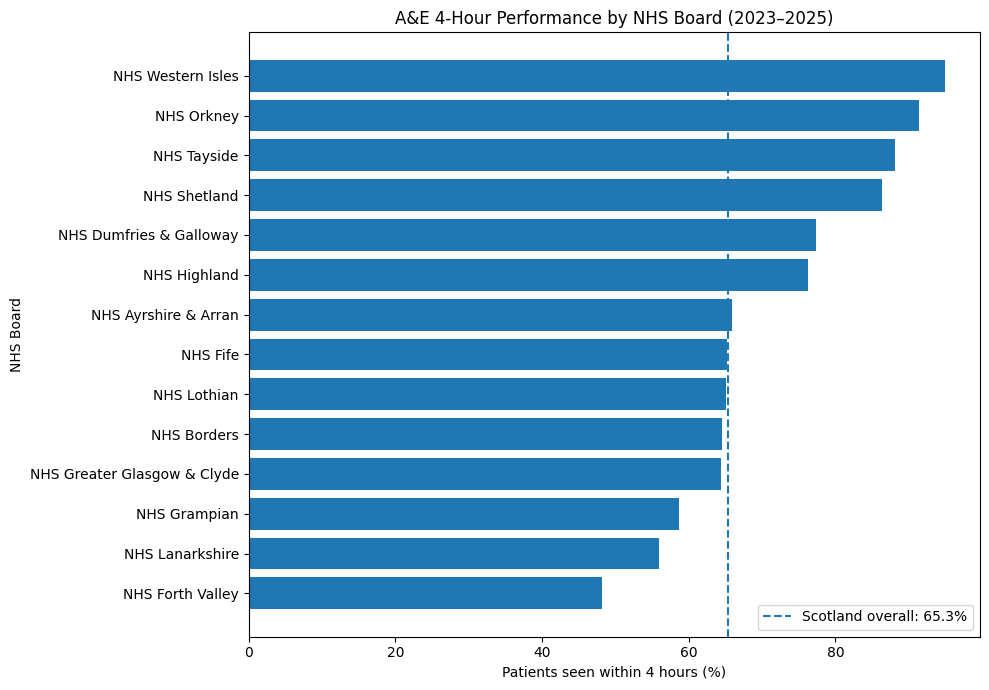

In [18]:
import matplotlib.pyplot as plt

plot_data = board_perf.sort_values("Performance_4hr_%")

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data["NHSBoardName"],
    plot_data["Performance_4hr_%"]
)

# Scotland overall performance
scotland_avg = (
    df_analysis["NumberWithin4HoursEpisode"].sum()
    / df_analysis["NumberOfAttendancesEpisode"].sum()
) * 100

plt.axvline(
    scotland_avg,
    linestyle="--",
    label=f"Scotland overall: {scotland_avg:.1f}%"
)

plt.xlabel("Patients seen within 4 hours (%)")
plt.ylabel("NHS Board")
plt.title("A&E 4-Hour Performance by NHS Board (2023–2025)")
plt.legend()

plt.tight_layout()
plt.show()

In [19]:
# NHS Lothian hospital-level performance

lothian_hospitals = (
    df_analysis[df_analysis["NHSBoardName"] == "NHS Lothian"]
    .groupby("LocationName")
    .agg(
        Total_Attendances=("NumberOfAttendancesEpisode", "sum"),
        Within_4_Hours=("NumberWithin4HoursEpisode", "sum"),
        Over_4_Hours=("NumberOver4HoursEpisode", "sum"),
        Over_8_Hours=("NumberOver8HoursEpisode", "sum"),
        Over_12_Hours=("NumberOver12HoursEpisode", "sum")
    )
    .reset_index()
)

lothian_hospitals["Performance_4hr_%"] = (
    lothian_hospitals["Within_4_Hours"]
    / lothian_hospitals["Total_Attendances"] * 100
).round(2)

lothian_hospitals = lothian_hospitals.sort_values(
    "Performance_4hr_%",
    ascending=False
)

lothian_hospitals

,LocationName,Total_Attendances,Within_4_Hours,Over_4_Hours,Over_8_Hours,Over_12_Hours,Performance_4hr_%
0,Royal Hospital for Children and Young People E...,163852,147591,16261,770,42,90.08
2,St John's Hospital,185702,123276,62426,20152,9439,66.38
1,Royal Infirmary Of Edinburgh,375588,201444,174144,64842,34739,53.63


In [20]:
# Monthly performance analysis for Royal Infirmary of Edinburgh

rie = df_analysis[
    df_analysis["LocationName"] == "Royal Infirmary Of Edinburgh"
].copy()

# Create monthly period
rie["Month"] = rie["WeekEndingDate"].dt.to_period("M")

rie_monthly = (
    rie.groupby("Month")
    .agg(
        Total_Attendances=("NumberOfAttendancesEpisode", "sum"),
        Within_4_Hours=("NumberWithin4HoursEpisode", "sum"),
        Over_8_Hours=("NumberOver8HoursEpisode", "sum"),
        Over_12_Hours=("NumberOver12HoursEpisode", "sum")
    )
    .reset_index()
)

rie_monthly["Performance_4hr_%"] = (
    rie_monthly["Within_4_Hours"]
    / rie_monthly["Total_Attendances"] * 100
).round(2)

rie_monthly["Month"] = rie_monthly["Month"].astype(str)

rie_monthly

,Month,Total_Attendances,Within_4_Hours,Over_8_Hours,Over_12_Hours,Performance_4hr_%
0,2023-01,10271,4434,2689,1654,43.17
1,2023-02,8684,3648,2426,1449,42.01
2,2023-03,8650,4128,1982,1122,47.72
3,2023-04,11077,5689,1758,707,51.36
4,2023-05,9374,4724,1250,487,50.39
5,2023-06,9432,5076,1275,537,53.82
6,2023-07,11755,6542,1449,574,55.65
7,2023-08,9845,5000,1561,691,50.79
8,2023-09,9766,4930,1324,477,50.48
9,2023-10,11716,5515,2247,1119,47.07


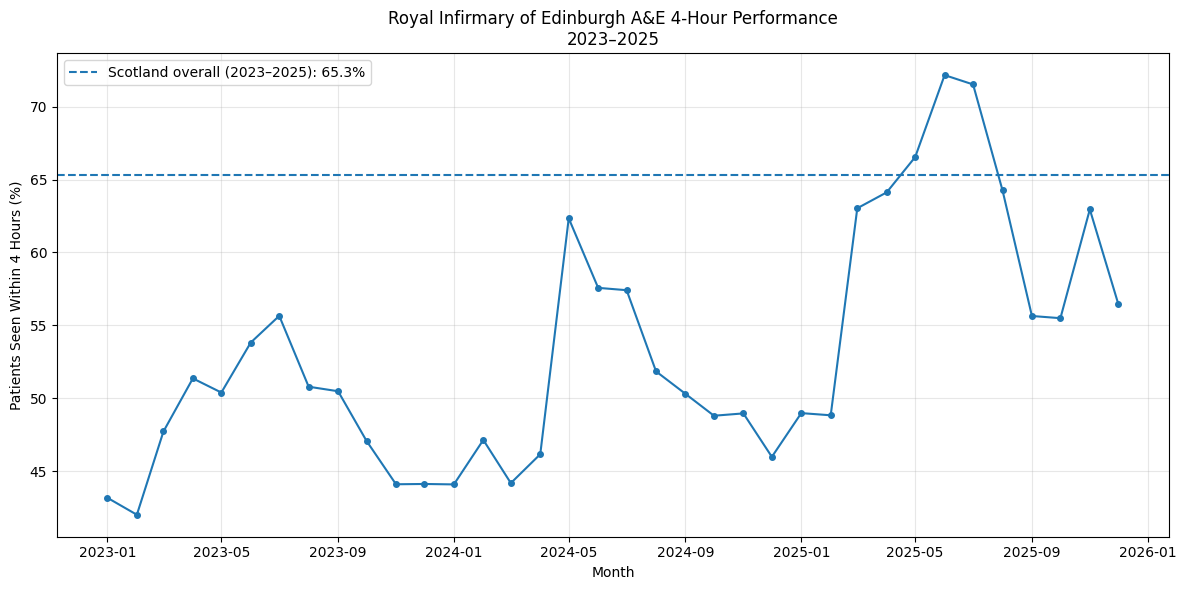

In [21]:
import matplotlib.pyplot as plt

# Convert Month to datetime for plotting
rie_monthly["MonthDate"] = pd.to_datetime(rie_monthly["Month"])

plt.figure(figsize=(12, 6))

plt.plot(
    rie_monthly["MonthDate"],
    rie_monthly["Performance_4hr_%"],
    marker="o",
    markersize=4
)

# Scotland overall benchmark
plt.axhline(
    scotland_avg,
    linestyle="--",
    label=f"Scotland overall (2023–2025): {scotland_avg:.1f}%"
)

plt.title(
    "Royal Infirmary of Edinburgh A&E 4-Hour Performance\n2023–2025"
)
plt.xlabel("Month")
plt.ylabel("Patients Seen Within 4 Hours (%)")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

In [22]:
# Relationship between patient volume and 4-hour performance

correlation = rie_monthly[
    ["Total_Attendances", "Performance_4hr_%"]
].corr().iloc[0, 1]

print(
    f"Correlation between attendance volume and "
    f"4-hour performance: {correlation:.3f}"
)

Correlation between attendance volume and 4-hour performance: 0.433


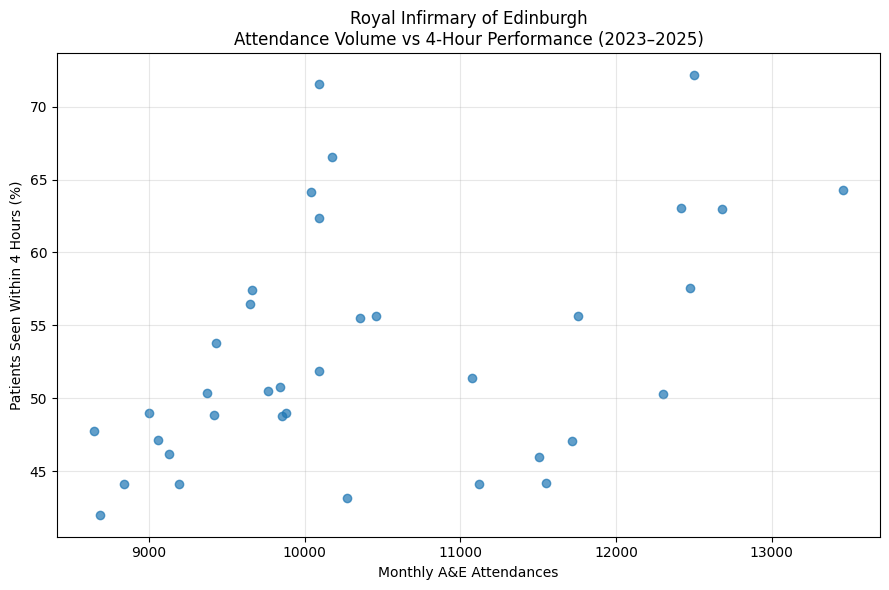

In [23]:
# Scatter plot: attendance volume vs 4-hour performance

plt.figure(figsize=(9, 6))

plt.scatter(
    rie_monthly["Total_Attendances"],
    rie_monthly["Performance_4hr_%"],
    alpha=0.7
)

plt.xlabel("Monthly A&E Attendances")
plt.ylabel("Patients Seen Within 4 Hours (%)")
plt.title(
    "Royal Infirmary of Edinburgh\n"
    "Attendance Volume vs 4-Hour Performance (2023–2025)"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
# Identify best and worst performing months

best_months = rie_monthly.nlargest(
    5, "Performance_4hr_%"
)[["Month", "Total_Attendances", "Performance_4hr_%"]]

worst_months = rie_monthly.nsmallest(
    5, "Performance_4hr_%"
)[["Month", "Total_Attendances", "Performance_4hr_%"]]

print("TOP 5 PERFORMANCE MONTHS")
print(best_months.to_string(index=False))

print("\nBOTTOM 5 PERFORMANCE MONTHS")
print(worst_months.to_string(index=False))

TOP 5 PERFORMANCE MONTHS
  Month  Total_Attendances  Performance_4hr_%
2025-06              12502              72.16
2025-07              10092              71.52
2025-05              10175              66.54
2025-08              13456              64.26
2025-04              10043              64.12

BOTTOM 5 PERFORMANCE MONTHS
  Month  Total_Attendances  Performance_4hr_%
2023-02               8684              42.01
2023-01              10271              43.17
2024-01               8838              44.09
2023-11               9197              44.10
2023-12              11123              44.12


In [25]:
# Royal Infirmary of Edinburgh annual performance

rie_monthly["Year"] = rie_monthly["Month"].astype(str).str[:4].astype(int)

rie_yearly = (
    rie_monthly.groupby("Year")
    .agg(
        Total_Attendances=("Total_Attendances", "sum"),
        Within_4_Hours=("Within_4_Hours", "sum")
    )
    .reset_index()
)

rie_yearly["Performance_4hr_%"] = (
    rie_yearly["Within_4_Hours"]
    / rie_yearly["Total_Attendances"] * 100
).round(2)

rie_yearly["YoY_Change_pp"] = (
    rie_yearly["Performance_4hr_%"].diff()
).round(2)

rie_yearly

,Year,Total_Attendances,Within_4_Hours,Performance_4hr_%,YoY_Change_pp
0,2023,120890,58649,48.51,NaN
1,2024,124444,62864,50.52,2.01
2,2025,130254,79931,61.37,10.85


In [26]:
# Compare Royal Infirmary of Edinburgh with Scotland overall

comparison = rie_yearly[
    ["Year", "Performance_4hr_%"]
].merge(
    yearly[["Year", "Performance_4hr_%"]],
    on="Year",
    suffixes=("_RIE", "_Scotland")
)

comparison["Gap_pp"] = (
    comparison["Performance_4hr_%_RIE"]
    - comparison["Performance_4hr_%_Scotland"]
).round(2)

comparison

,Year,Performance_4hr_%_RIE,Performance_4hr_%_Scotland,Gap_pp
0,2023,48.51,66.27,-17.76
1,2024,50.52,64.71,-14.19
2,2025,61.37,64.95,-3.58


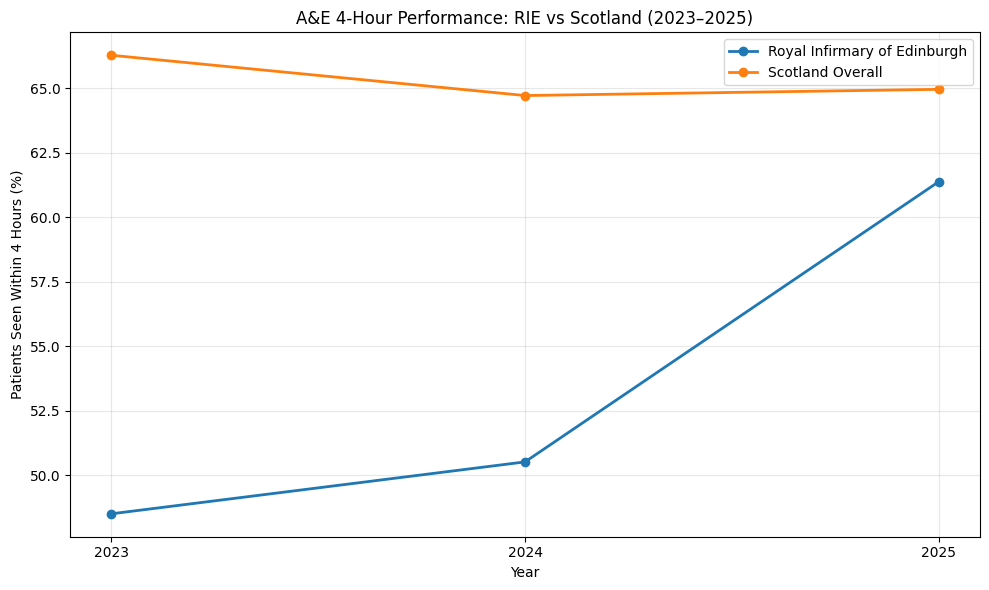

In [27]:
# RIE vs Scotland 4-hour performance

plt.figure(figsize=(10, 6))

plt.plot(
    comparison["Year"],
    comparison["Performance_4hr_%_RIE"],
    marker="o",
    linewidth=2,
    label="Royal Infirmary of Edinburgh"
)

plt.plot(
    comparison["Year"],
    comparison["Performance_4hr_%_Scotland"],
    marker="o",
    linewidth=2,
    label="Scotland Overall"
)

plt.xlabel("Year")
plt.ylabel("Patients Seen Within 4 Hours (%)")
plt.title("A&E 4-Hour Performance: RIE vs Scotland (2023–2025)")
plt.xticks(comparison["Year"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [28]:
# NHS Board performance change: 2023 vs 2025

board_year = (
    df_analysis.groupby(["NHSBoardName", "Year"])
    .agg(
        Total_Attendances=("NumberOfAttendancesEpisode", "sum"),
        Within_4_Hours=("NumberWithin4HoursEpisode", "sum")
    )
    .reset_index()
)

board_year["Performance_4hr_%"] = (
    board_year["Within_4_Hours"]
    / board_year["Total_Attendances"] * 100
).round(2)

# Convert years into columns for comparison
board_change = board_year.pivot(
    index="NHSBoardName",
    columns="Year",
    values="Performance_4hr_%"
).reset_index()

# Calculate change from 2023 to 2025
board_change["Change_2023_2025_pp"] = (
    board_change[2025] - board_change[2023]
).round(2)

board_change = board_change.sort_values(
    "Change_2023_2025_pp",
    ascending=False
)

board_change

Year,NHSBoardName,2023,2024,2025,Change_2023_2025_pp
9,NHS Lothian,62.91,63.26,69.01,6.10
10,NHS Orkney,88.84,91.59,93.41,4.57
4,NHS Forth Valley,49.44,46.76,48.25,-1.19
6,NHS Greater Glasgow & Clyde,65.26,63.80,64.02,-1.24
11,NHS Shetland,86.52,88.33,84.22,-2.30
2,NHS Dumfries & Galloway,79.18,76.26,76.58,-2.60
0,NHS Ayrshire & Arran,67.64,65.37,64.60,-3.04
3,NHS Fife,66.34,66.04,63.25,-3.09
1,NHS Borders,66.48,64.27,63.10,-3.38
12,NHS Tayside,90.26,87.84,86.48,-3.78


In [29]:
# Save analytical outputs for SQL / Power BI stages

yearly.to_csv(
    "../data/processed/scotland_yearly_performance.csv",
    index=False
)

board_year.to_csv(
    "../data/processed/nhs_board_yearly_performance.csv",
    index=False
)

board_change.to_csv(
    "../data/processed/nhs_board_performance_change.csv",
    index=False
)

rie_monthly.to_csv(
    "../data/processed/rie_monthly_performance.csv",
    index=False
)

rie_yearly.to_csv(
    "../data/processed/rie_yearly_performance.csv",
    index=False
)

print("Analytical datasets saved successfully.")

Analytical datasets saved successfully.
